In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


--- DISTRIBUSI TARGET LABEL ---
Status_Gagal_Bayar
0    1696
1    1304
Name: count, dtype: int64


C:\Users\Faiz\AppData\Local\Temp\ipykernel_16424\2252445236.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Status_Gagal_Bayar', palette=['#2ca02c', '#d62728'])


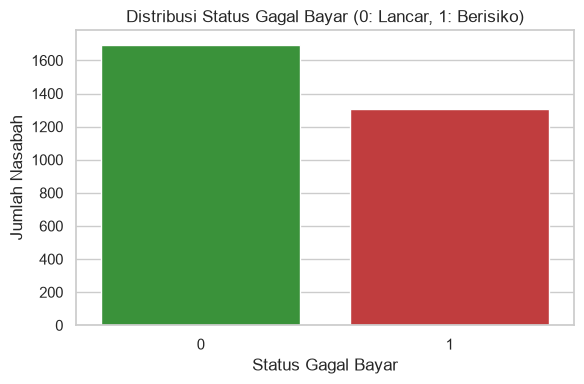


EVALUASI MODEL MACHINE LEARNING
Akurasi Model: 91.67%

Laporan Klasifikasi:
               precision    recall  f1-score   support

           0       0.91      0.95      0.93       339
           1       0.93      0.87      0.90       261

    accuracy                           0.92       600
   macro avg       0.92      0.91      0.91       600
weighted avg       0.92      0.92      0.92       600



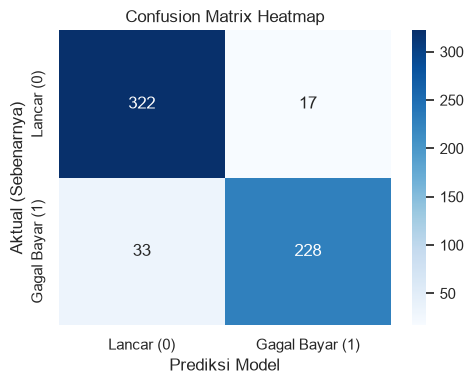

C:\Users\Faiz\AppData\Local\Temp\ipykernel_16424\2252445236.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importance, x='Importance', y='Fitur', palette='viridis')


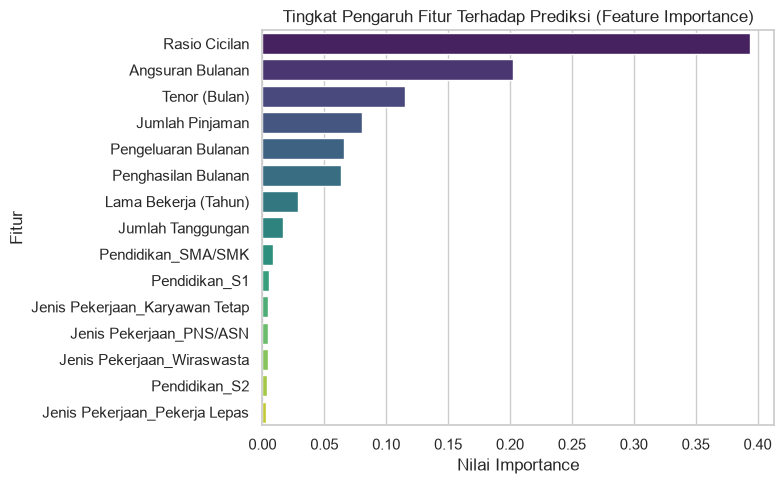


PREDIKSI NASABAH BARU
Hasil Prediksi     : Gagal Bayar (Berisiko)
Probabilitas Risiko: 80.05%


In [14]:
# Set tema visualisasi
sns.set_theme(style="whitegrid")

file_path = '../data nasabah.xlsx'
df = pd.read_excel(file_path, header=2)
# 2. GENERATE TARGET LABEL (STATUS GAGAL BAYAR)
np.random.seed(42)

skor_risiko = (
    (df['Rasio Cicilan'] > 0.40).astype(int) * 2.5
    + (df['Rasio Cicilan'] > 0.30).astype(int) * 1.5
    + ((df['Pengeluaran Bulanan'] + df['Angsuran Bulanan']) > df['Penghasilan Bulanan']).astype(int) * 3.0
    + (df['Jumlah Tanggungan'] >= 3).astype(int) * 1.0
    + (df['Lama Bekerja (Tahun)'] < 2).astype(int) * 1.2
    + np.random.normal(0, 0.8, size=len(df))
)

df['Status_Gagal_Bayar'] = np.where(skor_risiko > 2.8, 1, 0)

print("\n--- DISTRIBUSI TARGET LABEL ---")
print(df['Status_Gagal_Bayar'].value_counts())

# ==========================================
# GRAFIK 1: DISTRIBUSI TARGET LABEL
# ==========================================
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Status_Gagal_Bayar', palette=['#2ca02c', '#d62728'])
plt.title('Distribusi Status Gagal Bayar (0: Lancar, 1: Berisiko)')
plt.xlabel('Status Gagal Bayar')
plt.ylabel('Jumlah Nasabah')
plt.tight_layout()
plt.show()

# 3. PEMISAHAN FITUR (X) DAN TARGET (y)
X = df.drop(columns=['ID Nasabah', 'Status_Gagal_Bayar'])
y = df['Status_Gagal_Bayar']

fitur_kategori = ['Pendidikan', 'Jenis Pekerjaan']
fitur_numerik = [col for col in X.columns if col not in fitur_kategori]

# 4. PREPROCESSING PIPELINE
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), fitur_numerik),
        ('cat', OneHotEncoder(drop='first'), fitur_kategori),
    ]
)

model_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=100, max_depth=10, random_state=42
            ),
        ),
    ]
)

# 5. SPLIT DATA (TRAIN 80% / TEST 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. TRAINING MODEL
model_pipeline.fit(X_train, y_train)

# 7. EVALUASI MODEL
y_pred = model_pipeline.predict(X_test)

print("\n" + "=" * 50)
print("EVALUASI MODEL MACHINE LEARNING")
print("=" * 50)
print(f"Akurasi Model: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

# ==========================================
# GRAFIK 2: CONFUSION MATRIX HEATMAP
# ==========================================
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Lancar (0)', 'Gagal Bayar (1)'], yticklabels=['Lancar (0)', 'Gagal Bayar (1)'])
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual (Sebenarnya)')
plt.tight_layout()
plt.show()

# ==========================================
# GRAFIK 3: FEATURE IMPORTANCE (TINGKAT KEPENTINGAN FITUR)
# ==========================================
# Mengambil nama fitur setelah One-Hot Encoding
ohe_feature_names = list(model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(fitur_kategori))
all_feature_names = fitur_numerik + ohe_feature_names

importances = model_pipeline.named_steps['classifier'].feature_importances_
df_importance = pd.DataFrame({'Fitur': all_feature_names, 'Importance': importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_importance, x='Importance', y='Fitur', palette='viridis')
plt.title('Tingkat Pengaruh Fitur Terhadap Prediksi (Feature Importance)')
plt.xlabel('Nilai Importance')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

# 8. PREDIKSI DATA NASABAH BARU (SIMULASI)
data_baru = pd.DataFrame(
    [
        {
            'Pendidikan': 'SMA/SMK',
            'Jenis Pekerjaan': 'Karyawan Kontrak',
            'Lama Bekerja (Tahun)': 1,
            'Penghasilan Bulanan': 4500000,
            'Pengeluaran Bulanan': 3800000,
            'Jumlah Tanggungan': 3,
            'Jumlah Pinjaman': 30000000,
            'Tenor (Bulan)': 24,
            'Angsuran Bulanan': 1550000,
            'Rasio Cicilan': 0.344,
        }
    ]
)

prediksi = model_pipeline.predict(data_baru)[0]
probabilitas = model_pipeline.predict_proba(data_baru)[0][1]

print("\n" + "=" * 50)
print("PREDIKSI NASABAH BARU")
print("=" * 50)
print(f"Hasil Prediksi     : {'Gagal Bayar (Berisiko)' if prediksi == 1 else 'Lancar'}")
print(f"Probabilitas Risiko: {probabilitas * 100:.2f}%")